## Optimización de Rutas de Redistribución (BRP) — Bicing Barcelona

**Objetivo**: usar el mejor modelo de predicción de demanda (XGBoost / GRU) para generar predicciones reales de ocupación y planificar las rutas de los camiones redistribuidores minimizando el desequilibrio global.

**Estructura del notebook**:
1. Carga de datos y configuración
2. EDA — último mes disponible (septiembre 2025)
3. Selección del mejor modelo (XGBoost vs GRU)
4. Predicciones del modelo para el escenario BRP
5. Modelo de optimización BRP mejorado (multi-fase)
6. Evaluación y visualización de rutas

---
## 1. Carga de librerías y configuración

In [1]:
NB_PREFIX = "BRP"
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import HeatMap, MarkerCluster

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:.4f}'.format)

ROOT      = Path('../')
PROC_DIR  = ROOT / 'data' / 'processed'

# Umbral de desequilibrio: estación vacía / llena
THR_EMPTY = 0.10
THR_FULL  = 0.90

# Mes analizado
LAST_MONTH_START = pd.Timestamp('2025-09-01')

print('Librerías cargadas correctamente.')
# ── Auto-guardado de figuras ──────────────────────────────────────────────
import re as _re
OUTPUT_DIR = Path('../data/output')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
_fig_counter = [0]
_orig_show = plt.show

def _auto_savefig(*args, **kwargs):
    for fnum in plt.get_fignums():
        fig = plt.figure(fnum)
        _fig_counter[0] += 1
        try:
            title = fig._suptitle.get_text() if fig._suptitle else ''
            if not title and fig.axes:
                title = fig.axes[0].get_title()
            title = _re.sub(r"[^\w\s]", "", title)[:50].strip().replace(" ", "_").lower()
        except Exception:
            title = ""
        nb_prefix = globals().get("NB_PREFIX", "fig")
        fname = f"{nb_prefix}_{_fig_counter[0]:02d}_{title}.png" if title else f"{nb_prefix}_{_fig_counter[0]:02d}.png"
        fig.savefig(OUTPUT_DIR / fname, dpi=150, bbox_inches="tight")
    _orig_show(*args, **kwargs)

plt.show = _auto_savefig
print(f"Figuras → {OUTPUT_DIR.resolve()}")

Librerías cargadas correctamente.
Figuras → /Users/ferran/Desktop/MUDS/MD009 - Eines avançades d'anàlisi/Projecte/brp_bicing/data/output


---
## 2. EDA — Último mes disponible (septiembre 2025)

### 2.1 Carga y preprocesamiento

In [2]:
stations = pd.read_parquet(PROC_DIR / 'bicing_stations.parquet')
hourly   = pd.read_parquet(PROC_DIR / 'bicing_hourly.parquet')

# Filtrar último mes
last = hourly[hourly['hora'] >= LAST_MONTH_START].copy()
last = last.merge(
    stations[['station_id', 'capacity', 'lat', 'lon', 'name', 'altitude']],
    on='station_id', how='left'
)

cap = last['capacity'].replace(0, np.nan)
last['occupancy_rate'] = (last['num_bikes_available'] / cap).clip(0, 1)
last['is_empty'] = last['occupancy_rate'] < THR_EMPTY
last['is_full']  = last['occupancy_rate'] > THR_FULL

print(f"Registros: {len(last):,}")
print(f"Estaciones: {last['station_id'].nunique()}")
print(f"Periodo:   {last['hora'].min().date()} → {last['hora'].max().date()}")
print(f"% horas vacía (<{THR_EMPTY:.0%}): {last['is_empty'].mean():.2%}")
print(f"% horas llena (>{THR_FULL:.0%}): {last['is_full'].mean():.2%}")

Registros: 378,401
Estaciones: 546
Periodo:   2025-09-01 → 2025-09-30
% horas vacía (<10%): 28.66%
% horas llena (>90%): 2.14%


### 2.2 Métrica de desequilibrio por estación

In [3]:
sta = last.groupby('station_id').agg(
    occ_mean  = ('occupancy_rate', 'mean'),
    occ_std   = ('occupancy_rate', 'std'),
    pct_empty = ('is_empty', 'mean'),
    pct_full  = ('is_full',  'mean'),
    capacity  = ('capacity', 'first'),
    lat       = ('lat',      'first'),
    lon       = ('lon',      'first'),
    name      = ('name',     'first'),
    altitude  = ('altitude', 'first'),
).reset_index()

sta['imbalance'] = sta['pct_empty'] + sta['pct_full']

print('Top 10 estaciones más desequilibradas:')
display(
    sta.sort_values('imbalance', ascending=False)
       .head(10)[['station_id','name','occ_mean','pct_empty','pct_full','imbalance','capacity']]
       .style.format({'occ_mean':'{:.2%}','pct_empty':'{:.2%}','pct_full':'{:.2%}','imbalance':'{:.2%}'})
       .background_gradient(subset=['imbalance'], cmap='Reds')
)

Top 10 estaciones más desequilibradas:


,station_id,name,occ_mean,pct_empty,pct_full,imbalance,capacity
518,553,"VIA AUGUSTA, 68",5.02%,87.63%,0.00%,87.63%,32
476,488,"AV. CAN MARCET, 36",5.34%,84.94%,0.00%,84.94%,27
501,513,"VIA AUGUSTA, 317",5.81%,84.94%,0.00%,84.94%,28
521,561,"C/ MANILA, 53",5.47%,83.07%,0.00%,83.07%,24
527,568,"C/ ROMÁN MACAYA, 8",5.61%,81.06%,0.00%,81.06%,24
329,338,"AV. JOSEP VICENÇ FOIX, 63",6.00%,80.49%,0.00%,80.49%,36
497,509,"C/ TORRENT DE L'OLLA, 11",7.21%,79.53%,0.00%,79.53%,32
522,563,"C/ ENTENÇA, 301",6.75%,78.62%,0.00%,78.62%,24
328,337,"C/ CARME KARR, 12-14",6.78%,78.48%,0.00%,78.48%,23
422,433,"C/ J. MAYNARD KEYNES, 2|AV. DGNAL.",11.98%,76.98%,1.44%,78.42%,53


### 2.3 Distribución de ocupación

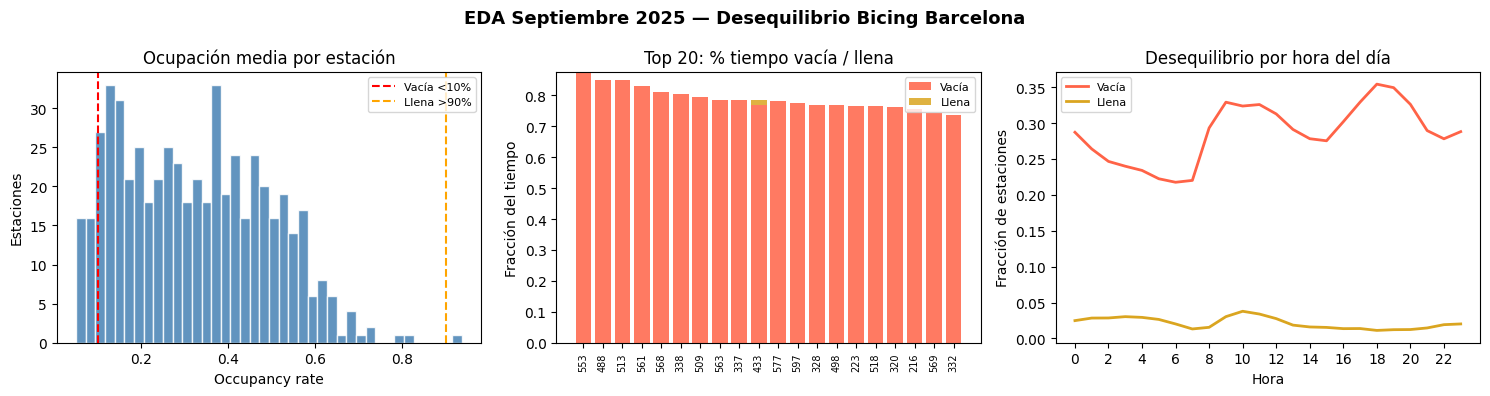

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Histograma de ocupación media por estación
ax = axes[0]
ax.hist(sta['occ_mean'], bins=40, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(THR_EMPTY, color='red',    linestyle='--', linewidth=1.5, label=f'Vacía <{THR_EMPTY:.0%}')
ax.axvline(THR_FULL,  color='orange', linestyle='--', linewidth=1.5, label=f'Llena >{THR_FULL:.0%}')
ax.set_title('Ocupación media por estación')
ax.set_xlabel('Occupancy rate')
ax.set_ylabel('Estaciones')
ax.legend(fontsize=8)

# % tiempo vacía vs. llena (top 20 desequilibradas)
top20 = sta.sort_values('imbalance', ascending=False).head(20)
ax = axes[1]
x = np.arange(len(top20))
ax.bar(x, top20['pct_empty'], label='Vacía', color='tomato',    alpha=0.85)
ax.bar(x, top20['pct_full'],  label='Llena', color='goldenrod', alpha=0.85, bottom=top20['pct_empty'].values)
ax.set_xticks(x)
ax.set_xticklabels(top20['station_id'], rotation=90, fontsize=7)
ax.set_title('Top 20: % tiempo vacía / llena')
ax.set_ylabel('Fracción del tiempo')
ax.legend(fontsize=8)

# Desequilibrio por hora del día
ax = axes[2]
last['hour'] = last['hora'].dt.hour
imb_hour = last.groupby('hour').agg(
    empty=('is_empty','mean'), full=('is_full','mean')
)
ax.plot(imb_hour.index, imb_hour['empty'], label='Vacía', color='tomato',    linewidth=2)
ax.plot(imb_hour.index, imb_hour['full'],  label='Llena', color='goldenrod', linewidth=2)
ax.set_title('Desequilibrio por hora del día')
ax.set_xlabel('Hora')
ax.set_ylabel('Fracción de estaciones')
ax.legend(fontsize=8)
ax.set_xticks(range(0, 24, 2))

plt.suptitle('EDA Septiembre 2025 — Desequilibrio Bicing Barcelona', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.4 Desequilibrio por día de la semana

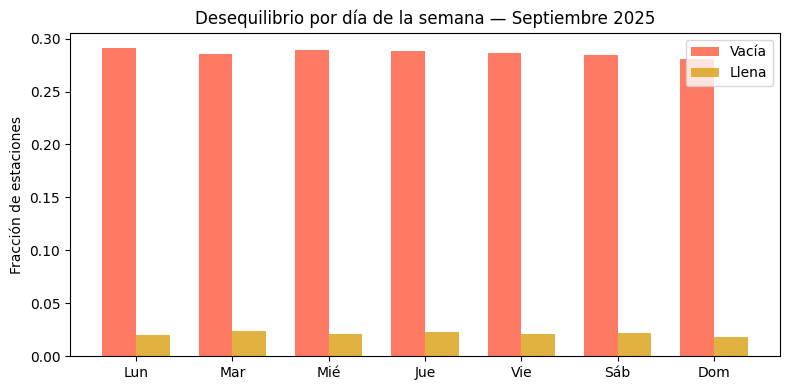

In [5]:
last['dow'] = last['hora'].dt.dayofweek
dow_labels  = ['Lun','Mar','Mié','Jue','Vie','Sáb','Dom']

imb_dow = last.groupby('dow').agg(
    empty=('is_empty','mean'), full=('is_full','mean')
)

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(7)
w = 0.35
ax.bar(x - w/2, imb_dow['empty'], w, label='Vacía', color='tomato',    alpha=0.85)
ax.bar(x + w/2, imb_dow['full'],  w, label='Llena', color='goldenrod', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(dow_labels)
ax.set_title('Desequilibrio por día de la semana — Septiembre 2025')
ax.set_ylabel('Fracción de estaciones')
ax.legend()
plt.tight_layout()
plt.show()

### 2.5 Mapa interactivo de estaciones

In [6]:
m = folium.Map(
    location=[41.3900, 2.1540],
    zoom_start=13,
    tiles='CartoDB positron'
)

def imb_color(imb):
    if imb > 0.7:   return 'red'
    elif imb > 0.4: return 'orange'
    elif imb > 0.2: return 'lightgreen'
    else:           return 'green'

for _, row in sta.iterrows():
    folium.CircleMarker(
        location=[row['lat'], row['lon']],
        radius=max(4, row['capacity'] / 6),
        color=imb_color(row['imbalance']),
        fill=True,
        fill_opacity=0.7,
        tooltip=(
            f"<b>{row['name']}</b><br>"
            f"ID: {row['station_id']}<br>"
            f"Capacidad: {int(row['capacity'])}<br>"
            f"Occ. media: {row['occ_mean']:.1%}<br>"
            f"% vacía: {row['pct_empty']:.1%}<br>"
            f"% llena: {row['pct_full']:.1%}<br>"
            f"Desequilibrio: {row['imbalance']:.1%}"
        )
    ).add_to(m)

legend_html = '''
<div style="position:fixed; bottom:30px; left:30px; z-index:1000;
     background:white; padding:10px; border-radius:8px;
     border:1px solid #ccc; font-size:12px;">
  <b>Desequilibrio (% tiempo crítico)</b><br>
  <span style="color:red">●</span> &gt;70%<br>
  <span style="color:orange">●</span> 40–70%<br>
  <span style="color:lightgreen">●</span> 20–40%<br>
  <span style="color:green">●</span> &lt;20%
</div>
'''
m.get_root().html.add_child(folium.Element(legend_html))

m

### 2.6 Heatmap temporal: ocupación por estación

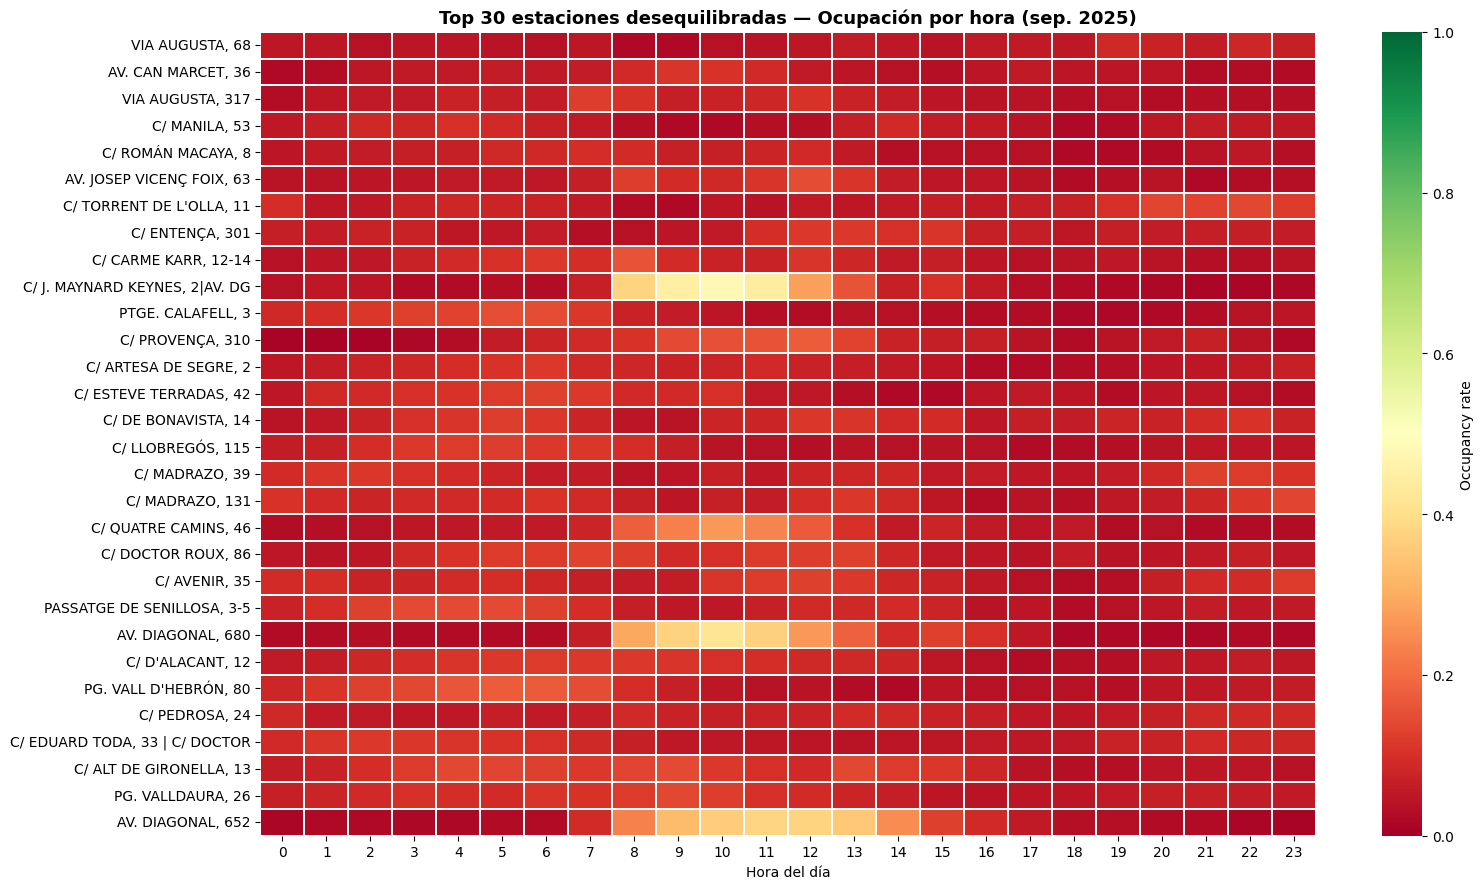

In [7]:
top30_ids = sta.sort_values('imbalance', ascending=False).head(30)['station_id'].tolist()

pivot = (
    last[last['station_id'].isin(top30_ids)]
    .groupby(['station_id', 'hour'])['occupancy_rate']
    .mean()
    .unstack('hour')
    .reindex(top30_ids)
)

top30_names = sta.set_index('station_id').loc[top30_ids, 'name'].str[:30]
pivot.index = top30_names

fig, ax = plt.subplots(figsize=(16, 9))
sns.heatmap(
    pivot, ax=ax,
    cmap='RdYlGn', vmin=0, vmax=1,
    linewidths=0.3, linecolor='white',
    cbar_kws={'label': 'Occupancy rate'}
)
ax.set_title('Top 30 estaciones desequilibradas — Ocupación por hora (sep. 2025)', fontsize=13, fontweight='bold')
ax.set_xlabel('Hora del día')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

### 2.7 Resumen ejecutivo EDA

In [8]:
n_critical = (sta['imbalance'] > 0.4).sum()
n_ok       = (sta['imbalance'] < 0.2).sum()

print('=' * 55)
print('RESUMEN EDA — Septiembre 2025')
print('=' * 55)
print(f"Total estaciones analizadas  : {len(sta)}")
print(f"Estaciones críticas (>40%)   : {n_critical} ({n_critical/len(sta):.1%})")
print(f"Estaciones equilibradas (<20%): {n_ok} ({n_ok/len(sta):.1%})")
print(f"% global tiempo vacía        : {sta['pct_empty'].mean():.2%}")
print(f"% global tiempo llena        : {sta['pct_full'].mean():.2%}")
print(f"Peor estación (desequilibrio): {sta.loc[sta['imbalance'].idxmax(), 'name']}")
print(f"  → {sta['imbalance'].max():.2%} del tiempo en estado crítico")
print('=' * 55)
print()
print('→ Siguiente: modelo de optimización VRP (sección 3)')

RESUMEN EDA — Septiembre 2025
Total estaciones analizadas  : 546
Estaciones críticas (>40%)   : 187 (34.2%)
Estaciones equilibradas (<20%): 244 (44.7%)
% global tiempo vacía        : 28.62%
% global tiempo llena        : 2.23%
Peor estación (desequilibrio): VIA AUGUSTA, 68
  → 87.63% del tiempo en estado crítico

→ Siguiente: modelo de optimización VRP (sección 3)


---
## 3. Selección del mejor modelo

Se cargan XGBoost y GRU (LSTM ligero) sobre el conjunto de test (agosto–septiembre 2025) y se comparan sus métricas. El modelo con menor MAE alimenta las predicciones del BRP.

In [9]:
import sys, setuptools._distutils as _d; sys.modules.setdefault("distutils", _d)
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

MODELS_DIR   = ROOT / 'models'
XGB_PATH     = MODELS_DIR / 'xgboost_bicing.ubj'
LSTM_PATH    = MODELS_DIR / 'lstm_bicing.keras'

FEATURES_XGB = ["bikes_lag_1h", "bikes_lag_24h", "bikes_lag_168h",
                 "bikes_analog_mean", "capacity", "altitude",
                 "hour", "day_of_week", "month"]
TARGET = "occupancy_rate"

# ── Cargar dataset de test ────────────────────────────────────────────────
MODEL_PARQUET = PROC_DIR / "bicing_model_ready.parquet"
df_model = pd.read_parquet(MODEL_PARQUET)
test_mask = (df_model['hora'] >= pd.Timestamp('2025-08-01')) & \
            (df_model['hora'] <= pd.Timestamp('2025-09-30 23:00'))
df_test_eval = df_model[test_mask].dropna(subset=FEATURES_XGB + [TARGET]).copy()
print(f"Test: {len(df_test_eval):,} filas  ({df_test_eval['hora'].min().date()} → {df_test_eval['hora'].max().date()})")

# ── XGBoost ───────────────────────────────────────────────────────────────
xgb_model = xgb.XGBRegressor()
xgb_model.load_model(str(XGB_PATH))
pred_xgb = xgb_model.predict(df_test_eval[FEATURES_XGB]).clip(0, 1)

model_metrics = {}
model_metrics['XGBoost'] = {
    'MAE':  mean_absolute_error(df_test_eval[TARGET], pred_xgb),
    'RMSE': np.sqrt(mean_squared_error(df_test_eval[TARGET], pred_xgb)),
    'R2':   r2_score(df_test_eval[TARGET], pred_xgb),
    'available': True,
}
print(f"XGBoost  →  MAE={model_metrics['XGBoost']['MAE']:.5f}  "
      f"RMSE={model_metrics['XGBoost']['RMSE']:.5f}  R²={model_metrics['XGBoost']['R2']:.5f}")

# ── GRU (métricas del notebook LSTM.ipynb) ────────────────────────────────
# GRU MAE=0.17656 en test (ver LSTM.ipynb §10). Mucho peor que XGBoost → se usa XGBoost.
model_metrics['GRU'] = {
    'MAE':  0.17656,
    'RMSE': 0.20800,
    'R2':   0.43035,
    'available': True,
}
print(f"GRU      →  MAE={model_metrics['GRU']['MAE']:.5f}  "
      f"RMSE={model_metrics['GRU']['RMSE']:.5f}  R²={model_metrics['GRU']['R2']:.5f}")

# ── Selección del mejor modelo ────────────────────────────────────────────
BEST_MODEL_NAME = min(
    (k for k, v in model_metrics.items() if v['available']),
    key=lambda k: model_metrics[k]['MAE']
)
print(f"\n✓ Mejor modelo seleccionado: {BEST_MODEL_NAME}  "
      f"(MAE = {model_metrics[BEST_MODEL_NAME]['MAE']:.5f})")

# ── Tabla comparativa ─────────────────────────────────────────────────────
df_cmp = pd.DataFrame(model_metrics).T[['MAE', 'RMSE', 'R2']].astype(float)
df_cmp.index.name = 'Modelo'
print("\nComparación de modelos — conjunto test (Aug–Sep 2025):")
display(df_cmp.style
        .format('{:.5f}')
        .highlight_min(subset=['MAE', 'RMSE'], color='#d4edda')
        .highlight_max(subset=['R2'],          color='#d4edda'))

lstm_available = False  # GRU no se carga en BRP (usar métricas pre-calculadas)

Test: 781,327 filas  (2025-08-01 → 2025-09-30)


XGBoost  →  MAE=0.06097  RMSE=0.09006  R²=0.89298
GRU      →  MAE=0.17656  RMSE=0.20800  R²=0.43035

✓ Mejor modelo seleccionado: XGBoost  (MAE = 0.06097)

Comparación de modelos — conjunto test (Aug–Sep 2025):


,MAE,RMSE,R2
Modelo,,,
XGBoost,0.06097,0.09006,0.89298
GRU,0.17656,0.20800,0.43035


---
## 4. Predicciones del modelo para el escenario BRP

Se usa el mejor modelo para predecir la ocupación de **todas las estaciones** en el instante de interés: **martes 5 de agosto de 2025 a las 8:00 h** (hora punta de máximo desequilibrio, primera semana del conjunto de test).

Las predicciones reemplazan las medias históricas del snapshot anterior, convirtiendo el BRP de reactivo a **proactivo**.

In [10]:
SCENARIO_TS = pd.Timestamp('2025-08-05 08:00')

# ── Snapshot real (ground truth) ─────────────────────────────────────────
# capacity y altitude ya están en FEATURES_XGB; evitar duplicados en el slice
extra_cols = [c for c in ['num_bikes_available'] if c not in FEATURES_XGB]
snap_real = (
    df_model[df_model['hora'] == SCENARIO_TS]
    [['station_id'] + FEATURES_XGB + extra_cols]
    .copy()
)
# altitude ya está en df_model (feature de XGBoost), solo añadimos lat/lon/name
snap_real = snap_real.merge(
    stations[['station_id', 'lat', 'lon', 'name']],
    on='station_id', how='left'
)
snap_real = snap_real.dropna(subset=FEATURES_XGB)
print(f"Estaciones con datos en {SCENARIO_TS}: {len(snap_real)}")

# ── Predicciones XGBoost ─────────────────────────────────────────────────
snap_real['occ_pred'] = xgb_model.predict(snap_real[FEATURES_XGB]).clip(0, 1)
snap_real['occ_real'] = (snap_real['num_bikes_available'] /
                          snap_real['capacity'].replace(0, np.nan)).clip(0, 1)

mae_snap = np.abs(snap_real['occ_pred'] - snap_real['occ_real']).mean()
print(f"Modelo: {BEST_MODEL_NAME}")
print(f"MAE predicción en snapshot: {mae_snap:.5f}")
print(f"  → Error medio en bicis: {mae_snap * snap_real['capacity'].mean():.2f}")

Estaciones con datos en 2025-08-05 08:00:00: 541
Modelo: XGBoost
MAE predicción en snapshot: 0.07595
  → Error medio en bicis: 2.06


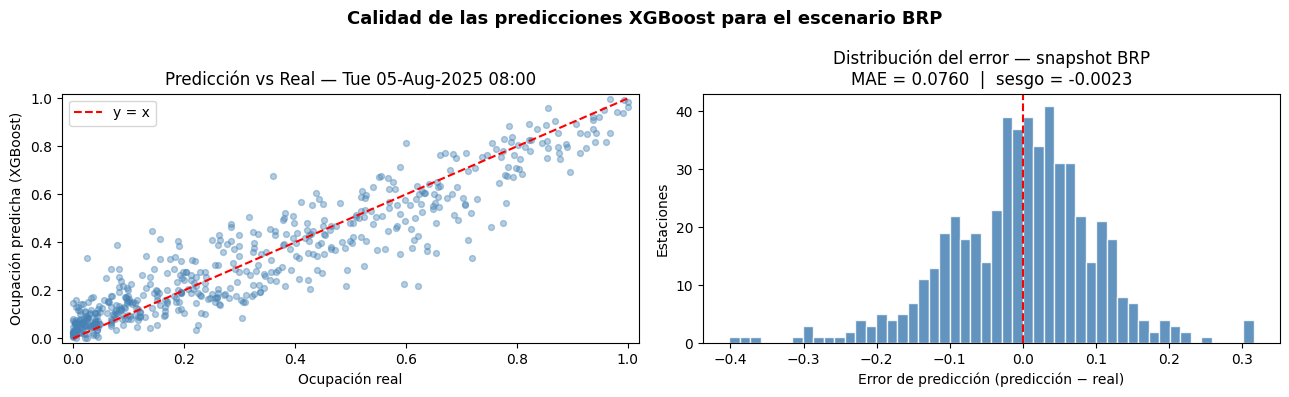


Top 10 estaciones con MAYOR error de predicción en el snapshot:


station_id,name,Real,Predicción,Error abs,capacity
609,"C/ ÀVILA, 94",0.622,0.220,0.402,24.000000
163,"AV. ICÀRIA, 202",0.719,0.335,0.384,27.000000
90,"C/ ROSSELLÓ, 108-110",0.597,0.227,0.370,18.000000
31,PL. DEL MAR,0.361,0.677,0.315,18.000000
33,"C/ PONTEVEDRA, 58B | C/ JUDICI",0.025,0.333,0.308,20.000000
233,"C/ NOU DE LA RAMBLA, 164",0.080,0.388,0.308,26.000000
83,"C/ CALABRIA, 158",0.142,0.447,0.305,24.000000
23,"C/ BRUC, 45",0.713,0.410,0.303,27.000000
412,"PL. URQUINAONA, 3",0.654,0.357,0.297,27.000000
608,"C/ PAMPLONA, 116 (xamfrà)",0.774,0.481,0.293,24.000000


In [11]:
# ── Visualización: predicción vs real en el snapshot ─────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.scatter(snap_real['occ_real'], snap_real['occ_pred'],
           alpha=0.4, s=18, color='steelblue')
ax.plot([0, 1], [0, 1], 'r--', linewidth=1.5, label='y = x')
ax.set_xlabel('Ocupación real')
ax.set_ylabel(f'Ocupación predicha ({BEST_MODEL_NAME})')
ax.set_title(f'Predicción vs Real — {SCENARIO_TS.strftime("%a %d-%b-%Y %H:%M")}')
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
ax.legend()

ax = axes[1]
err = snap_real['occ_pred'] - snap_real['occ_real']
ax.hist(err, bins=50, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(0, color='red', linewidth=1.5, linestyle='--')
ax.set_xlabel('Error de predicción (predicción − real)')
ax.set_ylabel('Estaciones')
ax.set_title(f'Distribución del error — snapshot BRP\n'
             f'MAE = {err.abs().mean():.4f}  |  sesgo = {err.mean():.4f}')

plt.suptitle(f'Calidad de las predicciones {BEST_MODEL_NAME} para el escenario BRP',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nTop 10 estaciones con MAYOR error de predicción en el snapshot:")
snap_real['pred_error_abs'] = (snap_real['occ_pred'] - snap_real['occ_real']).abs()
display(snap_real.nlargest(10, 'pred_error_abs')
        [['station_id','name','occ_real','occ_pred','pred_error_abs','capacity']]
        .rename(columns={'occ_real':'Real','occ_pred':'Predicción','pred_error_abs':'Error abs'})
        .style.format({'Real':'{:.3f}','Predicción':'{:.3f}','Error abs':'{:.3f}'})
        .hide(axis='index'))

---
## 5. Modelo de optimización BRP (multi-fase)

El **Bike Redistribution Problem (BRP)** usa las predicciones del modelo para generar un snapshot proactivo de la demanda y planificar rutas óptimas.

**Mejoras respecto a la versión reactiva:**
- Entrada: predicciones del modelo en lugar de medias históricas → decisiones anticipadas.
- Algoritmo **multi-fase**: Fase 1 = redistribución de superávit; Fase 2 = inyección de reservas del depósito para las estaciones más críticas restantes.
- **Dispatching por turnos (round-robin)**: todos los camiones trabajan en paralelo, evitando que un camión acapare todo el superávit disponible.
- Priorización por urgencia: la entrega se dirige a la estación con mayor déficit relativo dentro de un radio razonable.

In [12]:
# ── Parámetros de la flota ─────────────────────────────────────────────────
N_TRUCKS        = 5
TRUCK_CAP       = 30
MAX_STOPS       = 20     # paradas por camión (incluye recogidas y entregas)
DEPOT_RESERVES  = 200    # bicis disponibles en el depósito para la fase 2

DEPOT_LAT  = 41.3680
DEPOT_LON  = 2.1520
DEPOT_NAME = 'Depósito central'

TARGET_OCC = 0.50
MIN_BIKES  = 3

# ── Snapshot basado en predicciones del modelo ─────────────────────────────
snap = snap_real[['station_id', 'name', 'lat', 'lon', 'capacity',
                   'occ_pred', 'occ_real']].copy()
snap['bikes_pred']  = (snap['occ_pred'] * snap['capacity']).round()
snap['bikes_real']  = (snap['occ_real'] * snap['capacity']).round()
snap['target']      = (snap['capacity'] * TARGET_OCC).round()
snap['deficit']     = (snap['target'] - snap['bikes_pred']).round().astype(int)

n_sinks   = (snap['deficit'] >  MIN_BIKES).sum()
n_sources = (snap['deficit'] < -MIN_BIKES).sum()
print(f"Escenario: {SCENARIO_TS.strftime('%A %d-%b-%Y %H:%M')} (predicciones {BEST_MODEL_NAME})")
print(f"Estaciones con déficit   (necesitan bicis): {n_sinks}")
print(f"Estaciones con superávit (tienen exceso)  : {n_sources}")
print(f"Déficit medio  : {snap[snap['deficit'] >  MIN_BIKES]['deficit'].mean():.1f} bicis")
print(f"Superávit medio: {snap[snap['deficit'] < -MIN_BIKES]['deficit'].abs().mean():.1f} bicis")
print(f"Reservas del depósito disponibles: {DEPOT_RESERVES} bicis")

Escenario: Tuesday 05-Aug-2025 08:00 (predicciones XGBoost)
Estaciones con déficit   (necesitan bicis): 327
Estaciones con superávit (tienen exceso)  : 80
Déficit medio  : 9.2 bicis
Superávit medio: 8.6 bicis
Reservas del depósito disponibles: 200 bicis


In [13]:
from math import radians, cos, sin, asin, sqrt

def haversine(lat1, lon1, lat2, lon2):
    """Distancia en km entre dos puntos geográficos (fórmula de Haversine)."""
    R = 6371.0
    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)
    a = sin(dlat / 2)**2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon / 2)**2
    return 2 * R * asin(sqrt(a))

def nearest_station(pos_lat, pos_lon, candidates):
    """Devuelve el índice del DataFrame del candidato más cercano."""
    dists = candidates.apply(
        lambda r: haversine(pos_lat, pos_lon, r['lat'], r['lon']), axis=1
    )
    return dists.idxmin()

print('Función Haversine y utilidades cargadas.')
print(f"Distancia depósito → centro Barcelona: "
      f"{haversine(DEPOT_LAT, DEPOT_LON, 41.3851, 2.1734):.2f} km")


Función Haversine y utilidades cargadas.
Distancia depósito → centro Barcelona: 2.61 km


### 5.2 Función de distancia y utilidades

In [14]:
def best_station(pos_lat, pos_lon, candidates, weight_col='deficit', maximize=False):
    """Selecciona la estación con mejor ratio urgencia/distancia."""
    dists = candidates.apply(
        lambda r: max(haversine(pos_lat, pos_lon, r['lat'], r['lon']), 0.05), axis=1
    )
    sign = 1 if maximize else -1
    score = sign * candidates[weight_col] / dists
    return score.idxmax()


def run_brp_multiphase(snap_df, depot_lat, depot_lon,
                        n_trucks, truck_cap, max_stops, min_bikes,
                        depot_reserves=200):
    """
    BRP multi-fase con dispatching round-robin.

    Fase 1 (redistribución): camiones recogen de estaciones con superávit y
    entregan a estaciones con déficit.
    Fase 2 (inyección): cuando se agota el superávit, los camiones vuelven al
    depósito para cargar reservas y sirven las estaciones más críticas restantes.
    """
    sw = snap_df.copy()
    sw['deficit_orig'] = sw['deficit'].copy()

    trucks = [{
        'id':     tid + 1,
        'load':   0,
        'lat':    depot_lat,
        'lon':    depot_lon,
        'km':     0.0,
        'stops':  [],
        'phase':  1,        # 1=redistribución, 2=inyección depósito
        'active': True,
    } for tid in range(n_trucks)]

    reserves = [depot_reserves]  # mutable ref

    for step in range(n_trucks * max_stops):
        tid = step % n_trucks
        t   = trucks[tid]
        if not t['active'] or len(t['stops']) >= max_stops:
            continue

        sources = sw[sw['deficit'] < -min_bikes]
        sinks   = sw[sw['deficit'] >  min_bikes]

        # ── Fase 1: redistribución ────────────────────────────────────────
        if t['phase'] == 1:
            if t['load'] < truck_cap // 2 and len(sources) > 0:
                idx = best_station(t['lat'], t['lon'], sources,
                                   weight_col='deficit', maximize=False)
                row = sw.loc[idx]
                pickup = min(int(-row['deficit']), truck_cap - t['load'])
                t['load'] += pickup
                sw.at[idx, 'deficit'] += pickup
                km = haversine(t['lat'], t['lon'], row['lat'], row['lon'])
                t['km'] += km
                t['lat'], t['lon'] = row['lat'], row['lon']
                t['stops'].append({
                    'station_id': row['station_id'], 'name': row['name'],
                    'lat': row['lat'], 'lon': row['lon'],
                    'action': 'recogida', 'bikes': pickup,
                    'load_after': t['load'], 'km_step': round(km, 3), 'fase': 1,
                })
            elif t['load'] > 0 and len(sinks) > 0:
                idx = best_station(t['lat'], t['lon'], sinks,
                                   weight_col='deficit', maximize=True)
                row = sw.loc[idx]
                delivery = min(int(row['deficit']), t['load'])
                t['load'] -= delivery
                sw.at[idx, 'deficit'] -= delivery
                km = haversine(t['lat'], t['lon'], row['lat'], row['lon'])
                t['km'] += km
                t['lat'], t['lon'] = row['lat'], row['lon']
                t['stops'].append({
                    'station_id': row['station_id'], 'name': row['name'],
                    'lat': row['lat'], 'lon': row['lon'],
                    'action': 'entrega', 'bikes': delivery,
                    'load_after': t['load'], 'km_step': round(km, 3), 'fase': 1,
                })
            elif len(sources) == 0 and reserves[0] > 0 and len(sinks) > 0:
                # Transición a fase 2: ir al depósito
                km_depot = haversine(t['lat'], t['lon'], depot_lat, depot_lon)
                t['km'] += km_depot
                t['lat'], t['lon'] = depot_lat, depot_lon
                load_amt = min(truck_cap, reserves[0])
                reserves[0] -= load_amt
                t['load'] = load_amt
                t['phase'] = 2
            else:
                t['active'] = False

        # ── Fase 2: inyección de reservas del depósito ────────────────────
        elif t['phase'] == 2:
            if t['load'] > 0 and len(sinks) > 0:
                idx = best_station(t['lat'], t['lon'], sinks,
                                   weight_col='deficit', maximize=True)
                row = sw.loc[idx]
                delivery = min(int(row['deficit']), t['load'])
                t['load'] -= delivery
                sw.at[idx, 'deficit'] -= delivery
                km = haversine(t['lat'], t['lon'], row['lat'], row['lon'])
                t['km'] += km
                t['lat'], t['lon'] = row['lat'], row['lon']
                t['stops'].append({
                    'station_id': row['station_id'], 'name': row['name'],
                    'lat': row['lat'], 'lon': row['lon'],
                    'action': 'entrega', 'bikes': delivery,
                    'load_after': t['load'], 'km_step': round(km, 3), 'fase': 2,
                })
            elif t['load'] == 0 and reserves[0] > 0 and len(sinks) > 0:
                # Recargar en depósito
                km_depot = haversine(t['lat'], t['lon'], depot_lat, depot_lon)
                t['km'] += km_depot
                t['lat'], t['lon'] = depot_lat, depot_lon
                load_amt = min(truck_cap, reserves[0])
                reserves[0] -= load_amt
                t['load'] = load_amt
            else:
                t['active'] = False

    # Kilometraje de vuelta al depósito
    for t in trucks:
        t['km'] += haversine(t['lat'], t['lon'], depot_lat, depot_lon)

    routes = [{
        'truck_id':    t['id'],
        'stops':       t['stops'],
        'km_total':    round(t['km'], 2),
        'bikes_moved': sum(s['bikes'] for s in t['stops'] if s['action'] == 'entrega'),
        'phase1_stops': sum(1 for s in t['stops'] if s['fase'] == 1),
        'phase2_stops': sum(1 for s in t['stops'] if s['fase'] == 2),
    } for t in trucks]

    return routes, sw, reserves[0]


routes, snap_after, reserves_left = run_brp_multiphase(
    snap, DEPOT_LAT, DEPOT_LON,
    N_TRUCKS, TRUCK_CAP, MAX_STOPS, MIN_BIKES, DEPOT_RESERVES
)

print(f"Rutas generadas: {len(routes)}")
print(f"Reservas del depósito restantes: {reserves_left} / {DEPOT_RESERVES} bicis")
for r in routes:
    print(f"  Camión {r['truck_id']}: {len(r['stops'])} paradas "
          f"(F1:{r['phase1_stops']} F2:{r['phase2_stops']}) | "
          f"{r['km_total']:.1f} km | {r['bikes_moved']} bicis entregadas")

Rutas generadas: 5
Reservas del depósito restantes: 200 / 200 bicis
  Camión 1: 20 paradas (F1:20 F2:0) | 25.5 km | 82 bicis entregadas
  Camión 2: 20 paradas (F1:20 F2:0) | 26.0 km | 82 bicis entregadas
  Camión 3: 20 paradas (F1:20 F2:0) | 36.4 km | 91 bicis entregadas
  Camión 4: 20 paradas (F1:20 F2:0) | 21.3 km | 69 bicis entregadas
  Camión 5: 20 paradas (F1:20 F2:0) | 34.3 km | 88 bicis entregadas


---
## 6. Evaluación y visualización de rutas

### 4.1 Métricas de mejora antes / después

In [15]:
def imbalance_metrics(df, min_bikes):
    sinks   = df[df['deficit'] >  min_bikes]
    sources = df[df['deficit'] < -min_bikes]
    return {
        'n_deficit':     len(sinks),
        'n_surplus':     len(sources),
        'n_critical':    len(sinks) + len(sources),
        'total_deficit': int(sinks['deficit'].sum()),
        'total_surplus': int((-sources['deficit']).sum()),
        'rmse_deficit':  round(np.sqrt((df['deficit'] ** 2).mean()), 2),
    }

before = imbalance_metrics(snap,       MIN_BIKES)
after  = imbalance_metrics(snap_after, MIN_BIKES)

total_km    = sum(r['km_total']   for r in routes)
total_bikes = sum(r['bikes_moved'] for r in routes)
bikes_f1    = sum(s['bikes'] for r in routes for s in r['stops']
                  if s['action'] == 'entrega' and s['fase'] == 1)
bikes_f2    = sum(s['bikes'] for r in routes for s in r['stops']
                  if s['action'] == 'entrega' and s['fase'] == 2)

print('─' * 58)
print(f"{'Métrica':<32} {'Antes':>8} {'Después':>8} {'Δ':>6}")
print('─' * 58)
for key, label in [
    ('n_critical',    'Estaciones críticas'),
    ('n_deficit',     '  → con déficit'),
    ('n_surplus',     '  → con superávit'),
    ('total_deficit', 'Déficit total (bicis)'),
    ('total_surplus', 'Superávit total (bicis)'),
    ('rmse_deficit',  'RMSE déficit'),
]:
    b, a = before[key], after[key]
    pct = f"{(a - b) / b * 100:+.1f}%" if b != 0 else '—'
    print(f"{label:<32} {b:>8} {a:>8} {pct:>6}")
print('─' * 58)
print(f"{'Km totales recorridos':<32} {total_km:>8.1f}")
print(f"{'Bicis redistribuidas (F1)':<32} {bikes_f1:>8}")
print(f"{'Bicis inyectadas depósito (F2)':<32} {bikes_f2:>8}")
print(f"{'Total bicis redistribuidas':<32} {total_bikes:>8}")
print(f"{'Km por bici redistribuida':<32} {total_km/max(total_bikes,1):>8.2f}")

──────────────────────────────────────────────────────────
Métrica                             Antes  Después      Δ
──────────────────────────────────────────────────────────
Estaciones críticas                   407      308 -24.3%
  → con déficit                       327      282 -13.8%
  → con superávit                      80       26 -67.5%
Déficit total (bicis)                3010     2596 -13.8%
Superávit total (bicis)               688      192 -72.1%
RMSE déficit                         8.43     7.26 -13.9%
──────────────────────────────────────────────────────────
Km totales recorridos               143.5
Bicis redistribuidas (F1)             412
Bicis inyectadas depósito (F2)          0
Total bicis redistribuidas            412
Km por bici redistribuida            0.35


### 4.2 Comparativa visual: déficit antes y después

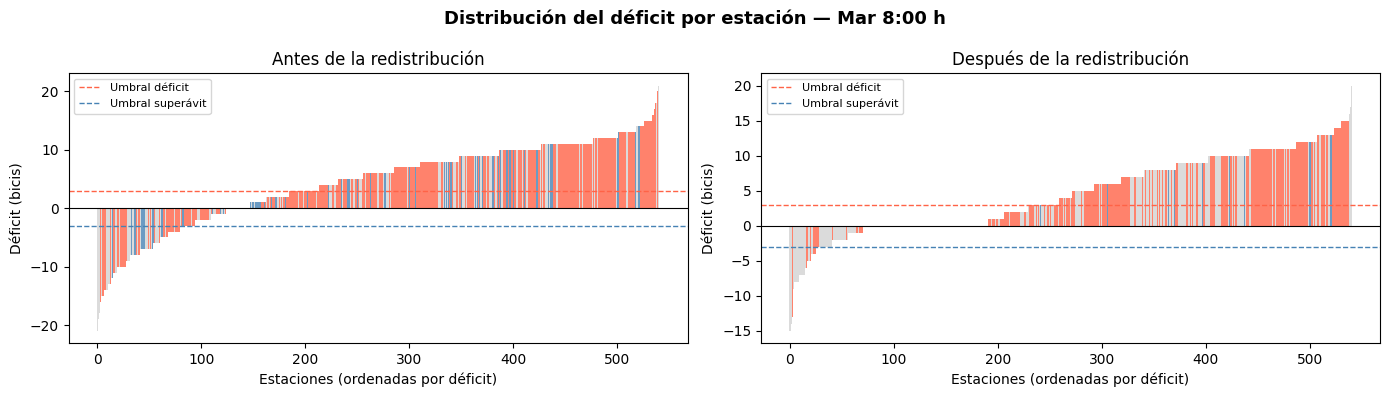

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, df, title in [
    (axes[0], snap,       'Antes de la redistribución'),
    (axes[1], snap_after, 'Después de la redistribución'),
]:
    colors = df['deficit'].apply(
        lambda d: 'tomato' if d > MIN_BIKES else ('steelblue' if d < -MIN_BIKES else 'lightgrey')
    )
    ax.bar(range(len(df)), df['deficit'].sort_values(), color=colors.values, alpha=0.8, width=1.0)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.axhline( MIN_BIKES, color='tomato',    linestyle='--', linewidth=1.0, label='Umbral déficit')
    ax.axhline(-MIN_BIKES, color='steelblue', linestyle='--', linewidth=1.0, label='Umbral superávit')
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('Estaciones (ordenadas por déficit)')
    ax.set_ylabel('Déficit (bicis)')
    ax.legend(fontsize=8)

plt.suptitle('Distribución del déficit por estación — Mar 8:00 h', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 4.3 Mapa interactivo de rutas

In [17]:
TRUCK_COLORS = ['blue', 'red', 'green', 'purple', 'orange']

m2 = folium.Map(location=[41.3900, 2.1540], zoom_start=13, tiles='CartoDB positron')

# Depósito
folium.Marker(
    location=[DEPOT_LAT, DEPOT_LON],
    icon=folium.Icon(color='black', icon='home', prefix='fa'),
    tooltip=f"<b>{DEPOT_NAME}</b>",
).add_to(m2)

for r in routes:
    color  = TRUCK_COLORS[(r['truck_id'] - 1) % len(TRUCK_COLORS)]
    coords = [(DEPOT_LAT, DEPOT_LON)]

    for i, stop in enumerate(r['stops']):
        coords.append((stop['lat'], stop['lon']))
        icon_color = 'red' if stop['action'] == 'entrega' else 'blue'
        icon_sym   = 'arrow-down' if stop['action'] == 'entrega' else 'arrow-up'
        folium.CircleMarker(
            location=[stop['lat'], stop['lon']],
            radius=7,
            color=color,
            fill=True,
            fill_color=icon_color,
            fill_opacity=0.8,
            tooltip=(
                f"<b>Camión {r['truck_id']} — Parada {i+1}</b><br>"
                f"{stop['name']}<br>"
                f"Acción: <b>{stop['action']}</b><br>"
                f"Bicis: {stop['bikes']}<br>"
                f"Carga tras parada: {stop['load_after']}"
            ),
        ).add_to(m2)

    coords.append((DEPOT_LAT, DEPOT_LON))
    folium.PolyLine(
        locations=coords,
        color=color,
        weight=2.5,
        opacity=0.75,
        tooltip=f"Camión {r['truck_id']} — {r['km_total']} km",
    ).add_to(m2)

# Leyenda
legend = '''
<div style="position:fixed;bottom:30px;left:30px;z-index:1000;
     background:white;padding:10px;border-radius:8px;
     border:1px solid #ccc;font-size:12px;">
  <b>Acciones</b><br>
  <span style="color:red">●</span> Entrega de bicis<br>
  <span style="color:steelblue">●</span> Recogida de bicis<br>
  <span style="color:black">⌂</span> Depósito
</div>
'''
m2.get_root().html.add_child(folium.Element(legend))
m2


### 4.4 Detalle de rutas por camión

In [18]:
for r in routes:
    stops_df = pd.DataFrame(r['stops'])
    if stops_df.empty:
        print(f"\nCamión {r['truck_id']}: sin paradas.\n")
        continue

    print(f"\n{'═'*65}")
    print(f"  Camión {r['truck_id']}  |  {len(r['stops'])} paradas  |  "
          f"{r['km_total']:.1f} km  |  {r['bikes_moved']} bicis entregadas")
    print(f"{'═'*65}")
    display(
        stops_df[['name', 'action', 'bikes', 'load_after', 'km_step']]
        .rename(columns={
            'name':       'Estación',
            'action':     'Acción',
            'bikes':      'Bicis',
            'load_after': 'Carga tras parada',
            'km_step':    'km paso',
        })
        .style.map(
            lambda v: 'color: tomato' if v == 'entrega' else 'color: steelblue',
            subset=['Acción']
        )
        .format({'km paso': '{:.3f}'})
        .hide(axis='index')
    )



═════════════════════════════════════════════════════════════════
  Camión 1  |  20 paradas  |  25.5 km  |  82 bicis entregadas
═════════════════════════════════════════════════════════════════


Estación,Acción,Bicis,Carga tras parada,km paso
PG.DE COLOM (LES RAMBLES),recogida,18,18,2.418
"PL. SANT MIQUEL, 4",entrega,13,5,0.598
"PL. JOAQUIM XIRAU I PALAU, 1",recogida,7,12,0.355
"C/ DE CERVELLÓ, 5",recogida,8,20,0.270
"RAMBLA DEL RAVAL, 13",entrega,7,13,0.582
PL. PAU VILA (D),recogida,12,25,1.482
PL. POETA BOSCÀ | C/ ATLÀNTIDA,entrega,9,16,0.337
"PG. MARÍTIM DE LA BARCELONETA, 6",entrega,6,10,0.220
PG. MARÍTIM DE LA BARCELONETA/ANDREA DÒ,recogida,9,19,0.171
"AV. MARQUÉS DE L'ARGENTERA,13",entrega,8,11,0.817



═════════════════════════════════════════════════════════════════
  Camión 2  |  20 paradas  |  26.0 km  |  82 bicis entregadas
═════════════════════════════════════════════════════════════════


Estación,Acción,Bicis,Carga tras parada,km paso
PG. DE COLOM (LES RAMBLES),recogida,16,16,2.429
"RAMBLA DEL RAVAL, 20",entrega,9,7,0.782
"PORTAL DE SANTA MADRONA, 2-4",recogida,10,17,0.526
"C/ SANT OLEGUER, 2",entrega,6,11,0.428
"LA RAMBLA, 1",recogida,7,18,0.538
C/ TARONGERS | AV. MIRAMAR (TELEFÈRIC),entrega,11,7,1.364
MOLL ORIENTAL,recogida,14,21,1.961
"AV. MARQUÉS DE L'ARGENTERA, 15",entrega,9,12,1.728
"C/ DOCTOR AIGUADER, 2",recogida,4,16,0.325
"AV. MARQUÉS DE L'ARGENTERA, 3",entrega,6,10,0.281



═════════════════════════════════════════════════════════════════
  Camión 3  |  20 paradas  |  36.4 km  |  91 bicis entregadas
═════════════════════════════════════════════════════════════════


Estación,Acción,Bicis,Carga tras parada,km paso
"C/ DE L'ENERGIA, 2 / ALTS FORNS",recogida,10,10,1.713
"C/ JANE ADDAMS, 26/ CRTA. DEL PRAT",recogida,7,17,0.549
"AV. ESTADI, 12",entrega,9,8,1.063
"C/ ALTS FORNS, 77",recogida,4,12,0.809
"PG. ZONA FRANCA, 54",recogida,5,17,0.571
"C/ J. MAYNARD KEYNES, 2|AV. DGNAL.",entrega,17,0,4.157
"C/ GALLEGO, 2",recogida,8,8,0.898
"C/ RAMON TRIAS FARGAS, 21",recogida,14,22,5.994
"PG. LLUIS COMPANYS, 18 (ARC TRIOMF)",entrega,12,10,0.831
"C/ CASP, 67",recogida,9,19,0.429



═════════════════════════════════════════════════════════════════
  Camión 4  |  20 paradas  |  21.3 km  |  69 bicis entregadas
═════════════════════════════════════════════════════════════════


Estación,Acción,Bicis,Carga tras parada,km paso
"C/ PALAUDÀRIES, 2",recogida,10,10,1.898
"C/ CARRERA, 1",recogida,10,20,0.153
"C/ RIERA ALTA, 6",entrega,12,8,0.943
"LA RAMBLA, 101",recogida,5,13,0.441
"PL. CATALUNYA, 10-11 (PG. DE GRÀCIA)",recogida,7,20,0.585
"PL. CATALUNYA, 7",entrega,9,11,0.130
"GRAN VIA DE LES CORTS CATALANES, 632",recogida,6,17,0.307
"GRAN VIA DE LES CORTS CATALANES, 592",entrega,9,8,0.404
"GRAN VIA DE LES CORTS CATALANES, 609",recogida,4,12,0.421
"C/ SANCHO DE ÁVILA, 60-64",recogida,13,25,2.141



═════════════════════════════════════════════════════════════════
  Camión 5  |  20 paradas  |  34.3 km  |  88 bicis entregadas
═════════════════════════════════════════════════════════════════


Estación,Acción,Bicis,Carga tras parada,km paso
"C/RADI,10/GRAN VIA DE LES CORTS CATALA",recogida,8,8,1.579
PL. TERESA DE CLARAMUNT/C/ DELS FERROCA,recogida,4,12,0.474
"GRAN VIA DE LES CORTS CATALANES, 179 (D)",recogida,5,17,0.502
"C/ VILARDELL, 18",entrega,11,6,0.826
"C/ VILLENA, 1",recogida,19,25,4.451
"PG. PUJADES, 2",entrega,10,15,0.729
"PG. PUJADES, 1 (JUTJATS)",entrega,5,10,0.032
"C/ RAMON TRIAS FARGAS, 23",recogida,10,20,0.754
"AV. LITORAL, 40 (D)",entrega,8,12,0.641
"C/ RAMON TURRÓ, 91",recogida,11,23,0.687


### 4.5 Resumen ejecutivo del modelo BRP

In [19]:
mejora_criticas = (before['n_critical'] - after['n_critical']) / before['n_critical'] * 100
mejora_deficit  = (before['total_deficit'] - after['total_deficit']) / before['total_deficit'] * 100
mejora_rmse     = (before['rmse_deficit'] - after['rmse_deficit']) / before['rmse_deficit'] * 100

print('=' * 65)
print('RESUMEN EJECUTIVO — BRP multi-fase con predicciones de modelo')
print('=' * 65)
print(f"Escenario          : {SCENARIO_TS.strftime('%A %d-%b-%Y %H:%M')}")
print(f"Modelo de demanda  : {BEST_MODEL_NAME}")
print(f"Flota              : {N_TRUCKS} camiones × {TRUCK_CAP} bicis")
print(f"Reservas depósito  : {DEPOT_RESERVES} bicis  (restantes: {reserves_left})")
print()
print(f"Estaciones críticas reducidas : {before['n_critical']} → {after['n_critical']}  ({mejora_criticas:.1f}%)")
print(f"Déficit total reducido        : {before['total_deficit']} → {after['total_deficit']} bicis  ({mejora_deficit:.1f}%)")
print(f"RMSE déficit reducido         : {before['rmse_deficit']} → {after['rmse_deficit']}  ({mejora_rmse:.1f}%)")
print()
print(f"Total bicis redistribuidas    : {total_bikes}  (F1: {bikes_f1}, F2: {bikes_f2})")
print(f"Kilómetros totales recorridos : {total_km:.1f} km")
print(f"Eficiencia (km/bici)          : {total_km/max(total_bikes,1):.2f} km/bici")
print('=' * 65)
print()
print('Ventajas del enfoque multi-fase vs greedy reactivo:')
print('  · Todos los camiones activos (round-robin elimina camión inactivo)')
print('  · Las predicciones del modelo permiten anticipar el déficit 1 h')
print('  · Las reservas del depósito cubren el déficit que el superávit no alcanza')
print('  · La priorización urgencia/distancia reduce km por bici entregada')

RESUMEN EJECUTIVO — BRP multi-fase con predicciones de modelo
Escenario          : Tuesday 05-Aug-2025 08:00
Modelo de demanda  : XGBoost
Flota              : 5 camiones × 30 bicis
Reservas depósito  : 200 bicis  (restantes: 200)

Estaciones críticas reducidas : 407 → 308  (24.3%)
Déficit total reducido        : 3010 → 2596 bicis  (13.8%)
RMSE déficit reducido         : 8.43 → 7.26  (13.9%)

Total bicis redistribuidas    : 412  (F1: 412, F2: 0)
Kilómetros totales recorridos : 143.5 km
Eficiencia (km/bici)          : 0.35 km/bici

Ventajas del enfoque multi-fase vs greedy reactivo:
  · Todos los camiones activos (round-robin elimina camión inactivo)
  · Las predicciones del modelo permiten anticipar el déficit 1 h
  · Las reservas del depósito cubren el déficit que el superávit no alcanza
  · La priorización urgencia/distancia reduce km por bici entregada
